# Notebook 7 — Multiple Sequence Alignment and Introductory Phylogenetics with Biopython

## Overview

This notebook introduces sequence comparison, multiple sequence alignment (MSA), alignment-column analysis, genetic distances, and introductory phylogenetics using Biopython.

The core workflow uses small, built-in example datasets and does not require internet access or external alignment software such as MAFFT. An optional section demonstrates how to retrieve records from NCBI.

> **Important scope note:** `Bio.Align.PairwiseAligner` performs pairwise alignment, not general multiple sequence alignment. The MSA in this notebook is a small, pre-aligned teaching example used to explain alignment columns and downstream analyses.

## Learning Objectives

By the end of this notebook, you should be able to:

1. Represent biological sequences with `Seq` and `SeqRecord`.
2. Compare DNA sequences using length, nucleotide composition, and sequence identity.
3. Perform and interpret pairwise alignments with `PairwiseAligner`.
4. Explain conserved sites, variable sites, and gaps in a multiple sequence alignment.
5. Summarize alignment columns using Python.
6. Calculate pairwise distances from aligned sequences.
7. construct a Neighbor-Joining (NJ) tree and interpret its limitations.
8. Export sequences, summaries, distance matrices, and trees to common file formats.

## 1. Introduction to Biopython Tools

The following modules will be used in this notebook.

| Module | Purpose |
|---|---|
| `Bio.Seq` | Represent and manipulate biological sequences |
| `Bio.SeqRecord` | Store a sequence with an identifier and description |
| `Bio.Align` | Perform pairwise sequence alignment |
| `Bio.Phylo` | Read, write, and display phylogenetic trees |
| `Bio.Phylo.TreeConstruction` | Calculate distances and construct trees |
| `Bio.Entrez` | Access NCBI Entrez services (optional; requires internet) |
| `Bio.SeqIO` | Read and write sequence files such as FASTA |

In [1]:
# Import the modules used throughout the notebook.
from collections import Counter
from pathlib import Path
import csv
import math

import matplotlib.pyplot as plt
import pandas as pd

from Bio import Align, Phylo, SeqIO
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
from Bio.Phylo.TreeConstruction import DistanceCalculator, DistanceTreeConstructor
from Bio.Align import MultipleSeqAlignment

OUTPUT_DIR = Path("notebook7_output")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Imports completed.")
print(f"Output directory: {OUTPUT_DIR.resolve()}")

Imports completed.
Output directory: C:\Users\mobin\Downloads\notebook7_output


## 2. Loading Biological Sequences

We will begin with short DNA sequences defined directly in the notebook. This makes the main exercises reproducible and available offline.

A `SeqRecord` combines a biological sequence with metadata such as an identifier and a description.

In [2]:
sequences = [
    SeqRecord(
        Seq("ATGCTAGCTAGCTACG"),
        id="Sequence_1",
        description="Example DNA sequence 1",
    ),
    SeqRecord(
        Seq("ATGCTAGATAGCTACG"),
        id="Sequence_2",
        description="Example DNA sequence 2",
    ),
    SeqRecord(
        Seq("ATGCTAGCTAGATACG"),
        id="Sequence_3",
        description="Example DNA sequence 3",
    ),
]

for record in sequences:
    print(f"{record.id}: {record.seq} (length={len(record.seq)})")

Sequence_1: ATGCTAGCTAGCTACG (length=16)
Sequence_2: ATGCTAGATAGCTACG (length=16)
Sequence_3: ATGCTAGCTAGATACG (length=16)


### Checkpoint

- What information is stored in `record.id`?
- How is `record.seq` different from a regular Python string?
- Why might a sequence description be useful when working with many records?

## 3. Basic Sequence Comparison

Before aligning sequences, inspect their lengths and nucleotide composition. For a simple comparison, we can also count mismatches at matching indices. This direct comparison is only appropriate when the sequences are already comparable position by position and have the same length.

**Important:** Percent identity calculated directly by index is not a substitute for alignment when insertions or deletions may be present.

In [3]:
def nucleotide_counts(sequence):
    """Return counts for the standard DNA nucleotides A, T, G, and C."""
    seq = str(sequence).upper()
    return {base: seq.count(base) for base in "ATGC"}


summary_rows = []
for record in sequences:
    row = {
        "id": record.id,
        "length": len(record.seq),
        **nucleotide_counts(record.seq),
    }
    summary_rows.append(row)

sequence_summary = pd.DataFrame(summary_rows).set_index("id")
sequence_summary

,length,A,T,G,C
id,,,,,
Sequence_1,16,4,4,4,4
Sequence_2,16,5,4,4,3
Sequence_3,16,5,4,4,3


In [4]:
def direct_comparison(seq_a, seq_b):
    """Compare equal-length sequences at matching indices.

    Returns the mismatch count and percent identity. This is a simple
    index-by-index comparison, not an alignment algorithm.
    """
    a, b = str(seq_a).upper(), str(seq_b).upper()
    if len(a) != len(b):
        raise ValueError("Direct comparison requires sequences of equal length.")
    mismatches = sum(base_a != base_b for base_a, base_b in zip(a, b))
    identity = 100 * (len(a) - mismatches) / len(a) if a else float("nan")
    return {"length": len(a), "mismatches": mismatches, "percent_identity": identity}


for i in range(len(sequences)):
    for j in range(i + 1, len(sequences)):
        result = direct_comparison(sequences[i].seq, sequences[j].seq)
        print(f"{sequences[i].id} vs {sequences[j].id}: {result}")

Sequence_1 vs Sequence_2: {'length': 16, 'mismatches': 1, 'percent_identity': 93.75}
Sequence_1 vs Sequence_3: {'length': 16, 'mismatches': 1, 'percent_identity': 93.75}
Sequence_2 vs Sequence_3: {'length': 16, 'mismatches': 2, 'percent_identity': 87.5}


## 4. Pairwise Alignment with Biopython

Pairwise alignment arranges two sequences so that likely corresponding residues can be compared. Gaps can represent insertions or deletions. The alignment score depends on the match, mismatch, and gap-scoring parameters.

The example below uses `Bio.Align.PairwiseAligner`. Its default settings are not a universal biological model; scoring parameters should be chosen for the sequence type and question being studied.

In [5]:
aligner = Align.PairwiseAligner()
aligner.mode = "global"
aligner.match_score = 2.0
aligner.mismatch_score = -1.0
aligner.open_gap_score = -2.0
aligner.extend_gap_score = -0.5

pairwise_alignment = aligner.align(sequences[0].seq, sequences[1].seq)[0]

print(pairwise_alignment)
print(f"Alignment score: {pairwise_alignment.score}")

target            0 ATGCTAGCTAGCTACG 16
                  0 |||||||.|||||||| 16
query             0 ATGCTAGATAGCTACG 16

Alignment score: 29.0


### Try changing the scoring parameters

Run the next cell after changing the mismatch or gap scores. Observe whether the preferred alignment changes. A score is useful for comparing alignments made under the same scoring scheme, but it is not itself a probability of common ancestry.

In [6]:
# Experiment with these values and rerun the alignment.
aligner.mismatch_score = -2.0
aligner.open_gap_score = -3.0

alternative_alignment = aligner.align(sequences[0].seq, sequences[1].seq)[0]
print(alternative_alignment)
print(f"Alternative alignment score: {alternative_alignment.score}")

target            0 ATGCTAGCTAGCTACG 16
                  0 |||||||.|||||||| 16
query             0 ATGCTAGATAGCTACG 16

Alternative alignment score: 28.0


## 5. Introduction to Multiple Sequence Alignment (MSA)

A multiple sequence alignment arranges three or more sequences in rows so that each column represents positions considered homologous or otherwise comparable. Gaps are inserted to represent inferred insertions or deletions.

To keep this notebook fully self-contained, the following is a **pre-aligned teaching example**. It is not produced by a general-purpose MSA algorithm.

In [7]:
aligned_sequences = [
    SeqRecord(Seq("ATGCTAGC"), id="Sequence_1", description="Pre-aligned example 1"),
    SeqRecord(Seq("ATG-TAGC"), id="Sequence_2", description="Pre-aligned example 2"),
    SeqRecord(Seq("ATGCTAGT"), id="Sequence_3", description="Pre-aligned example 3"),
]

alignment = MultipleSeqAlignment(aligned_sequences)

print(alignment)
print(f"Number of sequences: {len(alignment)}")
print(f"Alignment length: {alignment.get_alignment_length()}")

Alignment with 3 rows and 8 columns
ATGCTAGC Sequence_1
ATG-TAGC Sequence_2
ATGCTAGT Sequence_3
Number of sequences: 3
Alignment length: 8


### Key terms

- **Conserved site:** a column with the same nucleotide in every sequence, ignoring no differences.
- **Variable site:** a column containing more than one character among the sequences.
- **Gap:** a `-` character used to represent an insertion/deletion in an alignment.
- **Ambiguous character:** a symbol that does not specify a single nucleotide, such as `N`; this notebook's example does not contain ambiguous bases.

The biological interpretation of a column depends on the quality of the alignment and the assumptions used to create it.

## 6. Analyzing Alignment Columns

We will inspect each alignment column, count its characters, and classify it as fully conserved or variable. Gap-containing columns are counted separately. For this example, a column is considered fully conserved only if every sequence has the same non-gap character.

In [8]:
alignment_length = alignment.get_alignment_length()
num_sequences = len(alignment)

column_rows = []
for column_index in range(alignment_length):
    column = [str(record.seq[column_index]).upper() for record in alignment]
    counts = Counter(column)
    non_gap = [char for char in column if char != "-"]
    has_gap = "-" in column
    fully_conserved = (
        len(non_gap) == num_sequences
        and len(set(non_gap)) == 1
    )
    variable = len(set(column)) > 1

    column_rows.append({
        "column": column_index + 1,
        "characters": "".join(column),
        "counts": dict(counts),
        "has_gap": has_gap,
        "fully_conserved": fully_conserved,
        "variable": variable,
        "conservation_percent": 100 * max(counts.values()) / num_sequences,
    })

column_summary = pd.DataFrame(column_rows)
column_summary

,column,characters,counts,has_gap,fully_conserved,variable,conservation_percent
0,1,AAA,{'A': 3},False,True,False,100.000000
1,2,TTT,{'T': 3},False,True,False,100.000000
2,3,GGG,{'G': 3},False,True,False,100.000000
3,4,C-C,"{'C': 2, '-': 1}",True,False,True,66.666667
4,5,TTT,{'T': 3},False,True,False,100.000000
5,6,AAA,{'A': 3},False,True,False,100.000000
6,7,GGG,{'G': 3},False,True,False,100.000000
7,8,CCT,"{'C': 2, 'T': 1}",False,False,True,66.666667


Alignment columns: 8
Fully conserved columns: 6
Variable columns: 2
Columns containing gaps: 1


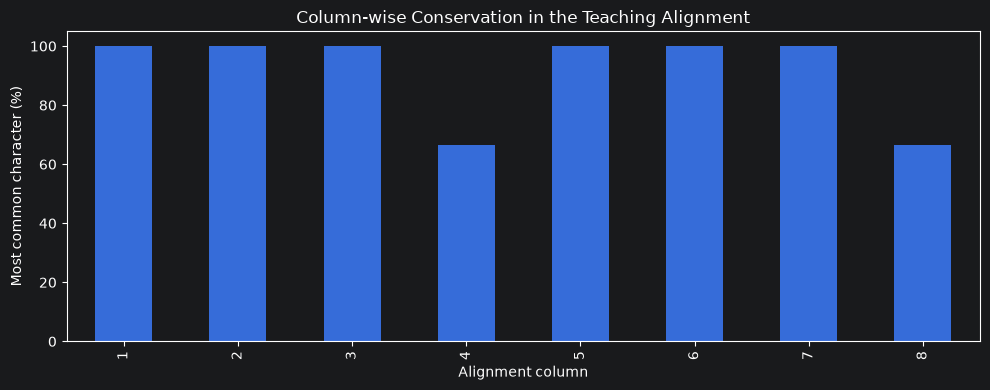

In [9]:
print(f"Alignment columns: {alignment_length}")
print(f"Fully conserved columns: {int(column_summary['fully_conserved'].sum())}")
print(f"Variable columns: {int(column_summary['variable'].sum())}")
print(f"Columns containing gaps: {int(column_summary['has_gap'].sum())}")

ax = column_summary.plot(
    x="column",
    y="conservation_percent",
    kind="bar",
    legend=False,
    figsize=(10, 4),
)
ax.set_xlabel("Alignment column")
ax.set_ylabel("Most common character (%)")
ax.set_ylim(0, 105)
ax.set_title("Column-wise Conservation in the Teaching Alignment")
plt.tight_layout()
plt.show()

## 7. Calculating Pairwise Distances

A distance matrix summarizes pairwise differences between aligned sequences. Biopython's `DistanceCalculator` supports several substitution models. Here we use the `identity` model, which converts identity into a distance of approximately `1 - identity`.

This is a simple uncorrected distance and does not correct for multiple substitutions at the same site. It is intended for introductory analysis, not as a universally appropriate evolutionary model.

In [10]:
calculator = DistanceCalculator("identity")
distance_matrix = calculator.get_distance(alignment)

print(distance_matrix)

Sequence_1  0.000000
Sequence_2  0.125000    0.000000
Sequence_3  0.125000    0.250000    0.000000
    Sequence_1  Sequence_2  Sequence_3


In [11]:
# Convert the lower-triangular DistanceMatrix into a square pandas DataFrame.
taxa = distance_matrix.names
distance_rows = []

for name in taxa:
    distance_rows.append([distance_matrix[name, other] for other in taxa])

distance_df = pd.DataFrame(distance_rows, index=taxa, columns=taxa)
distance_df

,Sequence_1,Sequence_2,Sequence_3
Sequence_1,0.000,0.125,0.125
Sequence_2,0.125,0.000,0.250
Sequence_3,0.125,0.250,0.000


### Interpreting the distance matrix

- A distance of `0` means the compared aligned sequences are identical under the chosen distance calculation.
- Larger values indicate more differences under that calculation.
- Distance estimates depend on the alignment, the treatment of gaps, and the chosen model.

For a very small teaching dataset, the estimates are illustrative and should not be overinterpreted.

## 8. Building a Neighbor-Joining Tree

Neighbor-Joining (NJ) constructs a tree from a distance matrix. The resulting tree is generally unrooted unless a root is added using an explicit method or an outgroup.

We will construct the tree from the distance matrix computed from the pre-aligned teaching example.

In [12]:
constructor = DistanceTreeConstructor()
nj_tree = constructor.nj(distance_matrix)

print(nj_tree)

Tree(rooted=False)
    Clade(branch_length=0, name='Inner1')
        Clade(branch_length=0.0, name='Sequence_1')
        Clade(branch_length=0.125, name='Sequence_2')
        Clade(branch_length=0.125, name='Sequence_3')


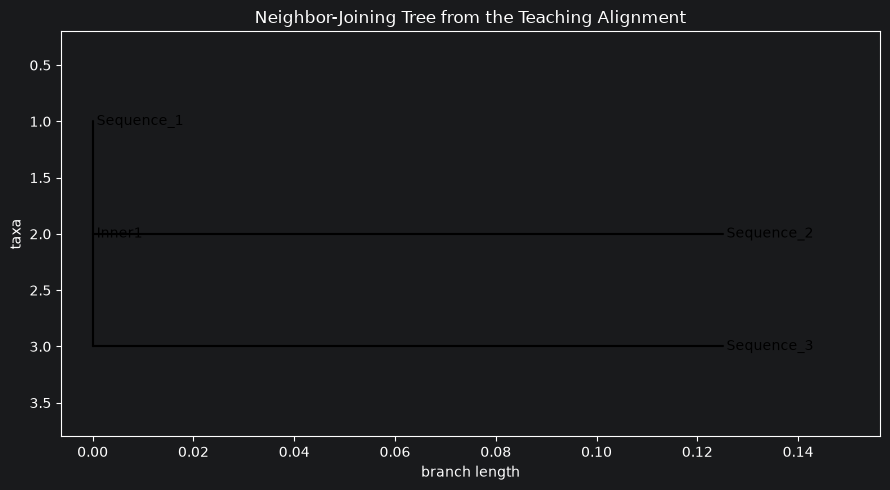

In [13]:
fig = plt.figure(figsize=(9, 5))
ax = fig.add_subplot(1, 1, 1)
Phylo.draw(nj_tree, axes=ax, do_show=False)
ax.set_title("Neighbor-Joining Tree from the Teaching Alignment")
plt.tight_layout()
plt.show()

## 9. Interpreting the Phylogenetic Tree

When interpreting the tree, consider these questions:

1. Which sequences are grouped together by the tree's branching pattern?
2. Which pairs have the smallest distance in the matrix?
3. What do branch lengths represent in this distance-based analysis?
4. How could a different alignment or distance model change the result?

**Caution:** an NJ tree is a hypothesis based on the supplied distances. It does not by itself prove a definitive evolutionary relationship. NJ trees are not inherently rooted, so do not infer the direction of evolution without additional information.

## 10. Optional: Fetching Sequences from NCBI

This section requires an internet connection. It is optional; all preceding sections use local example data.

NCBI Entrez requests should include a valid contact email. Replace the placeholder below with your own email before running the request. Use an appropriately narrow search term and respect NCBI usage guidance.

In [14]:
# OPTIONAL: Requires internet access.
# Replace the placeholder with a valid email address before running.
#
# from Bio import Entrez, SeqIO
# Entrez.email = "your.email@example.com"
#
# search_term = '"cytochrome c oxidase subunit I"[Gene] AND "Homo sapiens"[Organism]'
# with Entrez.esearch(db="nucleotide", term=search_term, retmax=3) as handle:
#     search_results = Entrez.read(handle)
#
# record_ids = search_results["IdList"]
# print("NCBI record IDs:", record_ids)
#
# if record_ids:
#     with Entrez.efetch(
#         db="nucleotide",
#         id=record_ids,
#         rettype="gb",
#         retmode="text",
#     ) as handle:
#         ncbi_records = list(SeqIO.parse(handle, "genbank"))
#
#     for record in ncbi_records:
#         print(record.id, record.description, len(record.seq))
#
#     SeqIO.write(ncbi_records, OUTPUT_DIR / "ncbi_records.fasta", "fasta")
#     print("Saved records to:", OUTPUT_DIR / "ncbi_records.fasta")

## 11. Exporting Results

The following cells save the example sequences, alignment-column summary, pairwise distance matrix, and NJ tree. The files are written to the `notebook7_output` directory.

In [15]:
# Export the unaligned example sequences as FASTA.
SeqIO.write(sequences, OUTPUT_DIR / "example_sequences.fasta", "fasta")

# Export the pre-aligned teaching example as aligned FASTA.
SeqIO.write(aligned_sequences, OUTPUT_DIR / "teaching_alignment.fasta", "fasta")

# Export alignment-column summary. Store the character counts as readable text.
column_export = column_summary.copy()
column_export["counts"] = column_export["counts"].apply(
    lambda value: "; ".join(f"{key}:{count}" for key, count in sorted(value.items()))
)
column_export.to_csv(OUTPUT_DIR / "alignment_column_summary.csv", index=False)

# Export pairwise distance matrix.
distance_df.to_csv(OUTPUT_DIR / "pairwise_distance_matrix.csv")

# Export the NJ tree in Newick format.
Phylo.write(nj_tree, OUTPUT_DIR / "neighbor_joining_tree.newick", "newick")

# Write a short text report.
report_lines = [
    "Notebook 7: Multiple Sequence Alignment and Introductory Phylogenetics",
    f"Number of aligned sequences: {len(alignment)}",
    f"Alignment length: {alignment.get_alignment_length()}",
    f"Fully conserved columns: {int(column_summary['fully_conserved'].sum())}",
    f"Variable columns: {int(column_summary['variable'].sum())}",
    f"Columns containing gaps: {int(column_summary['has_gap'].sum())}",
    "",
    "Pairwise distance matrix:",
    distance_df.to_string(),
    "",
    "Note: The alignment is a pre-aligned teaching example, not the output of a general-purpose MSA algorithm.",
]
(OUTPUT_DIR / "analysis_report.txt").write_text("\n".join(report_lines), encoding="utf-8")

print("Exported files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print("-", path.name)

Exported files:
- alignment_column_summary.csv
- analysis_report.txt
- example_sequences.fasta
- neighbor_joining_tree.newick
- pairwise_distance_matrix.csv
- teaching_alignment.fasta


## 12. Final Exercise

Complete the following tasks:

1. Add a fourth DNA sequence to the initial `sequences` list.
2. Compare its length and nucleotide composition with the other sequences.
3. Perform pairwise alignments between the new sequence and at least two existing sequences.
4. Create a new small, pre-aligned teaching example that includes the new sequence. Make sure every aligned row has the same length.
5. Recalculate the alignment-column summary and distance matrix.
6. Rebuild and plot the NJ tree.
7. Explain how your result might change if a different alignment or distance model were used.

### Reflection Questions

- Why is pairwise alignment not equivalent to multiple sequence alignment?
- Why should the alignment be checked before calculating distances?
- What information does an NJ tree summarize, and what does it not prove?
- Which parts of this notebook can run offline, and which part requires internet access?

## Summary

In this notebook, we used Biopython to represent sequences, compare DNA records, perform pairwise alignment, analyze a pre-aligned MSA example, calculate pairwise distances, construct a Neighbor-Joining tree, and export results.

The core workflow is self-contained and does not depend on MAFFT. For real biological datasets, use a suitable MSA method, inspect alignment quality, choose a defensible distance or substitution model, and interpret phylogenetic results with appropriate caution.